## Métodos Numéricos - Lista 03

Alunos
- Arthur Pontes de Miranda Ramos Soares
- Beatriz Rodrigues Cavalcante

In [ ]:
import math
from decimal import Decimal, getcontext

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt


## Questão 01

### a)

Com base na descrição do sistema e na lei de Hooke, podemos obter as seguintes equações, uma para cada massa.

$$
\begin{aligned}
f_1 - k_1 x_1 + k_2 (x_2 - x_1) &= 0 \\
f_2 - k_2 (x_2 - x_1) + k_3 (x_3 - x_2) &= 0 \\
f_3 - k_3 (x_3 - x_2) - k_4 x_3 &= 0
\end{aligned}
$$

Em que:

$$f_1 = 10 N; f_2 = 20 N; f_3 = 10 N$$
$$k_1 = 200 N/m; k_2 = 100 N/m; k_3 = 100 N/m; k_4 = 200 N/m;$$

Para obter o sistema na forma $Ax = b$, primeiro vamos isolar os termos com $x_i$.

$$
\begin{aligned}
f_1 &= k_1x_1-k_2(x_2-x_1)\\
f_2 &= k_2(x_2-x_1)-k_3(x_3-x_2)\\
f_3 &= k_3(x_3-x_2)+k_4x_3
\end{aligned}
$$

Depois, separar os valores de $x_i$.
$$
\begin{aligned}
(k_1+k_2)x_1-k_2x_2+0x_3 &= f_1\\
-k_2x_1+(k_2+k_3)x_2-k_3x_3 &= f_2\\
0x_1-k_3x_2+(k_3+k_4)x_3 &= f_3
\end{aligned}
$$

Colocando na forma matricial, temos:
$$
\begin{bmatrix}
k_1+k_2 & -k_2 & 0 \\
-k_2 & k_2+k_3 & -k_3 \\
0 & -k_3 & k_3+k_4
\end{bmatrix}
\begin{bmatrix}
x_1 \\
x_2 \\
x_3
\end{bmatrix}
=
\begin{bmatrix}
f_1 \\
f_2 \\
f_3
\end{bmatrix}
$$


### b)
Para garantir que haverá convergência usando o método de Gauss-Seidel, dado qualquer vetor inicial $x^{(0)}$, usaremos o seguinte teorema ([Wikipedia — Gauss–Seidel method, *Convergence*](https://en.wikipedia.org/wiki/Gauss%E2%80%93Seidel_method#Convergence)):

_"Se A é estritamente ou irredutivelmente diagonal dominante, então o método de Gauss-Seidel converge para a solução única de Ax = b, para qualquer escolha de $x^{(0)}$."_

Uma matriz é **irredutivelmente diagonal dominante** quando:
1. em todas as linhas, $|a_{ii}| \ge \sum_{j \ne i} |a_{ij}|$;
2. em pelo menos uma linha a desigualdade é estrita ($>$);
3. a matriz é irredutível.

Verificando para a nossa matriz $A$:

$$
A=
\begin{bmatrix}
k_1+k_2 & -k_2 & 0 \\
-k_2 & k_2+k_3 & -k_3 \\
0 & -k_3 & k_3+k_4
\end{bmatrix}
$$

1. Linha 1: $k_1+k_2 \ge k_2$. Linha 2: $k_2+k_3 \ge k_2+k_3$. Linha 3: $k_3+k_4 \ge k_3$. Todas valem, já que $k_i > 0$.
2. Nas linhas 1 e 3 a desigualdade é estrita, pois $k_1 > 0$ e $k_4 > 0$. Só a linha 2 dá igualdade, e por isso $A$ não é *estritamente* diagonal dominante.
3. $A$ é tridiagonal e os elementos logo acima e logo abaixo da diagonal ($-k_2$ e $-k_3$) são diferentes de zero. Isso a torna irredutível: cada massa está ligada à vizinha por uma mola, então o sistema não se separa em partes independentes.

Portanto, $A$ é irredutivelmente diagonal dominante e, pelo teorema, o método de Gauss-Seidel converge para a solução de $Ax = f$ para qualquer vetor inicial $x^{(0)}$.

### c)
Para o sistema $Ax = f$, as equações de Gauss-Seidel são:

$$
\begin{aligned}
x_1^{(k+1)}
&=\frac{f_1+k_2x_2^{(k)}}{k_1+k_2}\\[4pt]
x_2^{(k+1)}
&=\frac{f_2+k_2x_1^{(k+1)}+k_3x_3^{(k)}}{k_2+k_3}\\[4pt]
x_3^{(k+1)}
&=\frac{f_3+k_3x_2^{(k+1)}}{k_3+k_4}
\end{aligned}
$$

Precisamos representá-las na forma $x^{k + 1} = Tx^{k}$ + c. A primeira equação já tem essa forma. Podemos substituir $x_1^{(k+1)}$ na próxima.


$$
\begin{aligned}
x_2^{(k+1)}
&=\frac{f_2+k_2\left(\dfrac{f_1+k_2x_2^{(k)}}{k_1+k_2}\right)
+k_3x_3^{(k)}}{k_2+k_3}\\[4pt]
&=\frac{k_2^2}{(k_1+k_2)(k_2+k_3)}x_2^{(k)}
+\frac{k_3}{k_2+k_3}x_3^{(k)}
+\frac{f_2}{k_2+k_3}
+\frac{k_2f_1}{(k_1+k_2)(k_2+k_3)}
\end{aligned}
$$

O mesmo deve ser feito para $x_3^{(k + 1)}$.

$$
\begin{aligned}
x_3^{(k+1)}
&=\frac{k_2^2k_3}{(k_1+k_2)(k_2+k_3)(k_3+k_4)}x_2^{(k)}
+\frac{k_3^2}{(k_2+k_3)(k_3+k_4)}x_3^{(k)}\\[4pt]
&\quad+\frac{f_3}{k_3+k_4}
+\frac{k_3f_2}{(k_2+k_3)(k_3+k_4)}
+\frac{k_2k_3f_1}{(k_1+k_2)(k_2+k_3)(k_3+k_4)}
\end{aligned}
$$

Assim, obtemos T e c da forma estacionária.
$$
T=
\begin{bmatrix}
0 & \dfrac{k_2}{k_1+k_2} & 0\\
0 & \dfrac{k_2^2}{(k_1+k_2)(k_2+k_3)} & \dfrac{k_3}{k_2+k_3}\\
0 & \dfrac{k_2^2k_3}{(k_1+k_2)(k_2+k_3)(k_3+k_4)}
  & \dfrac{k_3^2}{(k_2+k_3)(k_3+k_4)}
\end{bmatrix}
$$

$$
c=
\begin{bmatrix}
\dfrac{f_1}{k_1+k_2}\\
\dfrac{f_2}{k_2+k_3}
+\dfrac{k_2f_1}{(k_1+k_2)(k_2+k_3)}\\
\dfrac{f_3}{k_3+k_4}
+\dfrac{k_3f_2}{(k_2+k_3)(k_3+k_4)}
+\dfrac{k_2k_3f_1}{(k_1+k_2)(k_2+k_3)(k_3+k_4)}
\end{bmatrix}
$$

Para verificar a convergência com base em T, vamos nos basear no teorema que diz que uma sequência $\{x^{k}\}_0^{∞}$ converge para uma solução única se e somente se $\rho(T) < 1$, ou seja, se o raio espectral de T for menor que 1.

Partindo da matriz T que obtivemos, vamos calcular seus autovalores $\lambda$.

$$
T-\lambda I=
\begin{bmatrix}
-\lambda & \dfrac{k_2}{k_1+k_2} & 0\\[8pt]
0 & \dfrac{k_2^2}{(k_1+k_2)(k_2+k_3)}-\lambda
& \dfrac{k_3}{k_2+k_3}\\[8pt]
0 & \dfrac{k_2^2k_3}{(k_1+k_2)(k_2+k_3)(k_3+k_4)}
& \dfrac{k_3^2}{(k_2+k_3)(k_3+k_4)}-\lambda
\end{bmatrix}
$$

Os autovalores são os valores de $\lambda$ para os quais o determinante dessa matriz é zero. Devido aos zeros na matriz $T - \lambda I$, o cálculo de seu determinante se reduz a:

$$
\det(T-\lambda I)
=
-\lambda
\begin{vmatrix}
\dfrac{k_2^2}{(k_1+k_2)(k_2+k_3)}-\lambda
& \dfrac{k_3}{k_2+k_3}\\[8pt]
\dfrac{k_2^2k_3}{(k_1+k_2)(k_2+k_3)(k_3+k_4)}
& \dfrac{k_3^2}{(k_2+k_3)(k_3+k_4)}-\lambda
\end{vmatrix}
$$

Fazendo o produto da diagonal principal menos o produto da outra diagonal, temos:

$$
\begin{aligned}
\det(T-\lambda I)
=-\lambda\Bigg[
&\left(
\frac{k_2^2}{(k_1+k_2)(k_2+k_3)}-\lambda
\right)
\left(
\frac{k_3^2}{(k_2+k_3)(k_3+k_4)}-\lambda
\right)\\
&-
\frac{k_3}{k_2+k_3}
\frac{k_2^2k_3}{(k_1+k_2)(k_2+k_3)(k_3+k_4)}
\Bigg]
\end{aligned}
$$

$$
\begin{aligned}
\det(T-\lambda I)
=-\lambda\Bigg[
&\frac{k_2^2k_3^2}{(k_1+k_2)(k_2+k_3)^2(k_3+k_4)}\\
&-\lambda\frac{k_2^2}{(k_1+k_2)(k_2+k_3)}
-\lambda\frac{k_3^2}{(k_2+k_3)(k_3+k_4)}
+\lambda^2\\
&-\frac{k_2^2k_3^2}{(k_1+k_2)(k_2+k_3)^2(k_3+k_4)}
\Bigg].
\end{aligned}
$$

Cancelando termos, ficamos com:

$$
\det(T-\lambda I)
=
-\lambda\left[
\lambda^2
-\lambda\frac{k_2^2}{(k_1+k_2)(k_2+k_3)}
-\lambda\frac{k_3^2}{(k_2+k_3)(k_3+k_4)}
\right]
$$

Logo,

$$
-\lambda^2\left[
\lambda
-\frac{k_2^2}{(k_1+k_2)(k_2+k_3)}
-\frac{k_3^2}{(k_2+k_3)(k_3+k_4)}
\right]=0.
$$

Um dos casos em que essa expressão se torna 0 é quando o conteúdo do colchete é 0, então:

$$
\lambda=
\frac{k_2^2}{(k_1+k_2)(k_2+k_3)}
+\frac{k_3^2}{(k_2+k_3)(k_3+k_4)}.
$$

Sendo as outras possibilidades de $\lambda$ = 0, então:

$$
\rho(T) =
\lambda=
\frac{k_2^2}{(k_1+k_2)(k_2+k_3)}
+\frac{k_3^2}{(k_2+k_3)(k_3+k_4)}=
\frac{k_2}{k_1+k_2}
\cdot \frac{k_2}{k_2+k_3}
+\frac{k_3}{k_2+k_3}
\cdot \frac{k_3}{k_3+k_4}
$$

Observando a expressão, vemos que todos os termos são menores que 1, pois o denominador é sempre maior que o numerador, dado que $k_i > 0, \: i = 1, 2, 3$.


Nesse caso, podemos substituir duas das frações por 1 e ficamos com um valor que é maior que o raio espectral $\rho(T)$:

$$
\rho(T) <
1
\cdot \frac{k_2}{k_2+k_3}
+\frac{k_3}{k_2+k_3}
\cdot 1
$$

Reorganizando a expressão temos:

$$
\rho(T) <
1
\cdot \frac{k_2}{k_2+k_3}
+\frac{k_3}{k_2+k_3}
\cdot 1
= \frac{k_2+k_3}{k_2+k_3}
= 1
$$

Ou seja, como substituimos a primeira e a quarta fração por 1 e obtivemos um valor de 1 para a expressão, a versão da expressão com as frações que são menores que 1, sempre trará um valor de $\rho(T)$ menor que 1.

Portanto, pelo teorema, a iteração $x^{(k+1)}=Tx^{(k)}+c$ converge para uma única solução, dado qualquer vetor inicial $x^{(0)}$.

### d)

In [ ]:
def gauss_seidel(A, b, x0, tol=1e-5, max_iter=1000):
    size = len(b)
    previous = list(x0)
    current = [0.0] * size

    for iteration in range(1, max_iter + 1):
        for i in range(size):
            lower_sum = sum(A[i][j] * current[j] for j in range(i))
            upper_sum = sum(A[i][j] * previous[j] for j in range(i + 1, size))

            current[i] = (b[i] - lower_sum - upper_sum) / A[i][i]

        # Norma infinita da diferença
        difference = max(abs(current[i] - previous[i]) for i in range(size))
        if difference < tol:
            return current, iteration, difference

        previous = current.copy()

    raise RuntimeError(f"Critério de parada não foi atingido depois de {max_iter} iterações.")

In [ ]:
k1 = 200.0
k2 = 100.0
k3 = 100.0
k4 = 200.0

A = [
    [k1 + k2, -k2, 0.0],
    [-k2, k2 + k3, -k3],
    [0.0, -k3, k3 + k4],
]

b = [10.0, 20.0, 10.0]
x0 = [0.0, 0.0, 0.0]

solution, iterations, difference = gauss_seidel(A, b, x0)

for index, xi in enumerate(solution, start=1):
    print(f"x{index} = {xi:.10f} m")

print(f"Iterations: {iterations}")
print(f"Maximum change: {difference:.10e} m")


x1 = 0.0999957662 m
x2 = 0.1999957662 m
x3 = 0.0999985887 m
Iterations: 10
Maximum change: 8.4675439042e-06 m


## Questão 2

In [ ]:
heights = [0.0, 0.5, 1.0, 1.5, 2.0]
volumes = [0.0, 620.0, 1480.0, 2570.0, 4020.0]
target_height = 1.25

### a) Mínimos quadrados com $p_2(h) = a_0 + a_1h + a_2h^2$

Queremos os coeficientes que minimizam a soma dos quadrados dos erros:

$$
E(a_0, a_1, a_2) = \sum_{i=1}^{5} \left( V_i - a_0 - a_1h_i - a_2h_i^2 \right)^2
$$

Igualando a zero as derivadas parciais de $E$ em relação a $a_0$, $a_1$ e $a_2$, obtemos as equações normais:

$$
\begin{bmatrix}
n & \sum h_i & \sum h_i^2 \\
\sum h_i & \sum h_i^2 & \sum h_i^3 \\
\sum h_i^2 & \sum h_i^3 & \sum h_i^4
\end{bmatrix}
\begin{bmatrix}
a_0 \\ a_1 \\ a_2
\end{bmatrix}
=
\begin{bmatrix}
\sum V_i \\ \sum h_iV_i \\ \sum h_i^2V_i
\end{bmatrix}
$$

O código abaixo monta esse sistema a partir da tabela e o resolve por eliminação de Gauss com pivoteamento parcial.

In [ ]:
def least_squares_system(xs, ys, degree):
    size = degree + 1

    # power_sums[p] = soma de x_i^p, para p = 0, ..., 2*degree
    power_sums = [sum(x ** p for x in xs) for p in range(2 * degree + 1)]

    A = [[power_sums[i + j] for j in range(size)] for i in range(size)]
    b = [sum(y * x ** i for x, y in zip(xs, ys)) for i in range(size)]

    return A, b


def gaussian_elimination(A, b):
    size = len(b)
    augmented = [row[:] + [b[i]] for i, row in enumerate(A)]

    for col in range(size):
        # Pivoteamento parcial: usa a linha com maior |pivô|
        pivot_row = max(range(col, size), key=lambda r: abs(augmented[r][col]))
        augmented[col], augmented[pivot_row] = augmented[pivot_row], augmented[col]

        for row in range(col + 1, size):
            factor = augmented[row][col] / augmented[col][col]
            for j in range(col, size + 1):
                augmented[row][j] -= factor * augmented[col][j]

    # Substituição regressiva
    x = [0.0] * size
    for i in range(size - 1, -1, -1):
        known_sum = sum(augmented[i][j] * x[j] for j in range(i + 1, size))
        x[i] = (augmented[i][size] - known_sum) / augmented[i][i]

    return x


def evaluate_polynomial(coefficients, x):
    return sum(c * x ** i for i, c in enumerate(coefficients))

In [ ]:
A, b = least_squares_system(heights, volumes, degree=2)

print("Sistema normal A a = b:")
for row, bi in zip(A, b):
    print("  [" + "  ".join(f"{value:8.3f}" for value in row) + f" ] = {bi:10.3f}")

coefficients = gaussian_elimination(A, b)

print()
for index, coefficient in enumerate(coefficients):
    print(f"a{index} = {coefficient:.6f}")

volume_least_squares = evaluate_polynomial(coefficients, target_height)
print(f"\np2({target_height}) ≈ {volume_least_squares:.4f} L")

Com os dados da tabela, o sistema normal é:

$$
\begin{bmatrix}
5 & 5 & 7{,}5 \\
5 & 7{,}5 & 12{,}5 \\
7{,}5 & 12{,}5 & 22{,}125
\end{bmatrix}
\begin{bmatrix}
a_0 \\ a_1 \\ a_2
\end{bmatrix}
=
\begin{bmatrix}
8\,690 \\ 13\,685 \\ 23\,497{,}5
\end{bmatrix}
$$

A solução é $a_0 = 10$, $a_1 = 918$ e $a_2 = 540$. Logo:

$$
p_2(h) = 10 + 918h + 540h^2, \qquad p_2(1{,}25) = 10 + 1\,147{,}5 + 843{,}75 = 2\,001{,}25 \text{ L}
$$

### b) Polinômio interpolador de Lagrange $p_4(h)$

Com os cinco pontos $(h_k, V_k)$, o polinômio interpolador de Lagrange é:

$$
p_4(h) = \sum_{k=0}^{4} V_k \, L_k(h), \qquad L_k(h) = \prod_{j \ne k} \frac{h - h_j}{h_k - h_j}
$$

Cada $L_k$ vale 1 em $h_k$ e 0 nos outros nós, então $p_4$ passa exatamente por todos os pontos da tabela.

In [ ]:
def lagrange_basis(xs, k, x):
    result = 1.0
    for j, xj in enumerate(xs):
        if j != k:
            result *= (x - xj) / (xs[k] - xj)
    return result


def lagrange_interpolation(xs, ys, x):
    return sum(ys[k] * lagrange_basis(xs, k, x) for k in range(len(xs)))

In [ ]:
for k in range(len(heights)):
    basis_value = lagrange_basis(heights, k, target_height)
    print(f"L{k}({target_height}) = {basis_value:9.6f}  ->  V{k} * L{k} = {volumes[k] * basis_value:10.4f}")

volume_lagrange = lagrange_interpolation(heights, volumes, target_height)
print(f"\np4({target_height}) ≈ {volume_lagrange:.5f} L")

Em $h = 1{,}25$, os polinômios de base valem:

$$
L_0 = \tfrac{3}{128},\quad L_1 = -\tfrac{5}{32},\quad L_2 = \tfrac{45}{64},\quad L_3 = \tfrac{15}{32},\quad L_4 = -\tfrac{5}{128}
$$

Logo:

$$
p_4(1{,}25) = 0 \cdot \tfrac{3}{128} - 620 \cdot \tfrac{5}{32} + 1\,480 \cdot \tfrac{45}{64} + 2\,570 \cdot \tfrac{15}{32} - 4\,020 \cdot \tfrac{5}{128} = 1\,991{,}40625 \text{ L}
$$

### c) Método de Neville

O método de Neville calcula o valor do interpolador em um ponto $x$ sem construir o polinômio. Ele combina interpoladores de grau menor usando a recorrência:

$$
Q_{i,j} = \frac{(x - x_{i-j})\,Q_{i,j-1} - (x - x_i)\,Q_{i-1,j-1}}{x_i - x_{i-j}}, \qquad Q_{i,0} = y_i
$$

$Q_{i,j}$ é o valor em $x$ do polinômio de grau $j$ que interpola os pontos $x_{i-j}, \dots, x_i$. O último elemento, $Q_{4,4}$, usa os cinco pontos e por isso coincide com $p_4(x)$.

In [ ]:
def neville(xs, ys, x):
    n = len(xs)
    Q = [[None] * n for _ in range(n)]

    for i in range(n):
        Q[i][0] = ys[i]

    for j in range(1, n):
        for i in range(j, n):
            Q[i][j] = (
                (x - xs[i - j]) * Q[i][j - 1] - (x - xs[i]) * Q[i - 1][j - 1]
            ) / (xs[i] - xs[i - j])

    return Q

In [ ]:
Q = neville(heights, volumes, target_height)

print("Tabela de Neville (h = 1,25 m):\n")
print(f"{'h_i':>5} | " + " | ".join(f"{'Q_i,' + str(j):>11}" for j in range(len(heights))))
print("-" * 75)
for i, row in enumerate(Q):
    cells = [f"{value:11.5f}" if value is not None else " " * 11 for value in row]
    print(f"{heights[i]:5.2f} | " + " | ".join(cells))

volume_neville = Q[-1][-1]
print(f"\nVolume estimado em h = {target_height} m: {volume_neville:.5f} L")

| $h_i$ | $Q_{i,0}$ | $Q_{i,1}$ | $Q_{i,2}$ | $Q_{i,3}$ | $Q_{i,4}$ |
|---|---|---|---|---|---|
| 0,0 | 0 | | | | |
| 0,5 | 620 | 1 550 | | | |
| 1,0 | 1 480 | 1 910 | 2 000 | | |
| 1,5 | 2 570 | 2 025 | 1 996,25 | 1 996,875 | |
| 2,0 | 4 020 | 1 845 | 1 980 | 1 988,125 | **1 991,40625** |

O valor final, $Q_{4,4} = 1\,991{,}40625$ L, é igual ao de Lagrange no item b), como esperado: os dois métodos calculam o mesmo polinômio interpolador de grau 4, só que de formas diferentes.

Comparando os itens: o ajuste por mínimos quadrados dá $2\,001{,}25$ L e a interpolação dá $1\,991{,}41$ L, uma diferença de cerca de 0,5%. Como o enunciado diz que as medições têm pequenos erros experimentais, o ajuste por mínimos quadrados tende a ser mais confiável. Ele não é obrigado a passar exatamente por cada ponto e assim suaviza o ruído. O interpolador de grau 4 passa por todos os pontos e acaba incorporando também os erros de medição.

## Questão 3

In [ ]:
def sample_function(expression_str, interval, n):
    time_symbol = sp.Symbol("t")
    expression = sp.sympify(expression_str, locals={"t": time_symbol})

    start, end = interval
    step = (end - start) / (n - 1)

    time_values = np.linspace(start, end, n)

    current_values = [
        float(expression.subs(time_symbol, time).evalf())
        for time in time_values
    ]

    return time_values, current_values

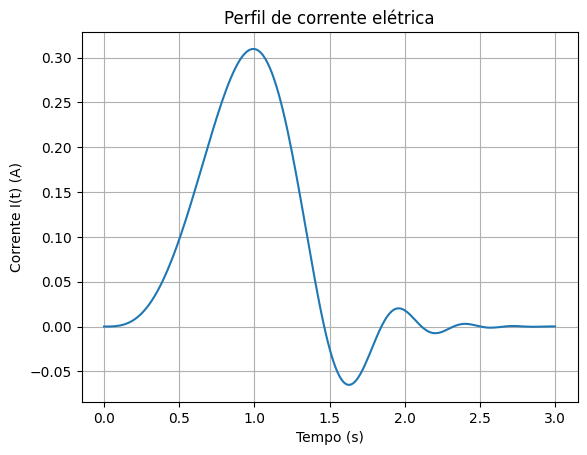

In [ ]:
time_values, current_values = sample_function(
    expression_str="exp(-t**2) * sin(t**3)",
    interval=(0, 3),
    n=200,
)

plt.plot(time_values, current_values)
plt.xlabel("Tempo (s)")
plt.ylabel("Corrente I(t) (A)")
plt.title("Perfil de corrente elétrica")
plt.grid(True)
plt.show()

### b) Calcular derivada usando diferenças centradas

In [ ]:
def centered_derivative(time_values, current_values):
    if len(time_values) < 3:
        raise ValueError("O método da diferença centrada de 3 pontos requer pelo menos 3 ponto, né?")

    step = time_values[1] - time_values[0]

    derivative_values = []

    for index in range(1, len(time_values) - 1):
        previous_value = current_values[index - 1]
        next_value = current_values[index + 1]

        derivative = (next_value - previous_value) / (2 * step)
        derivative_values.append(derivative)

    return time_values[1:-1], derivative_values

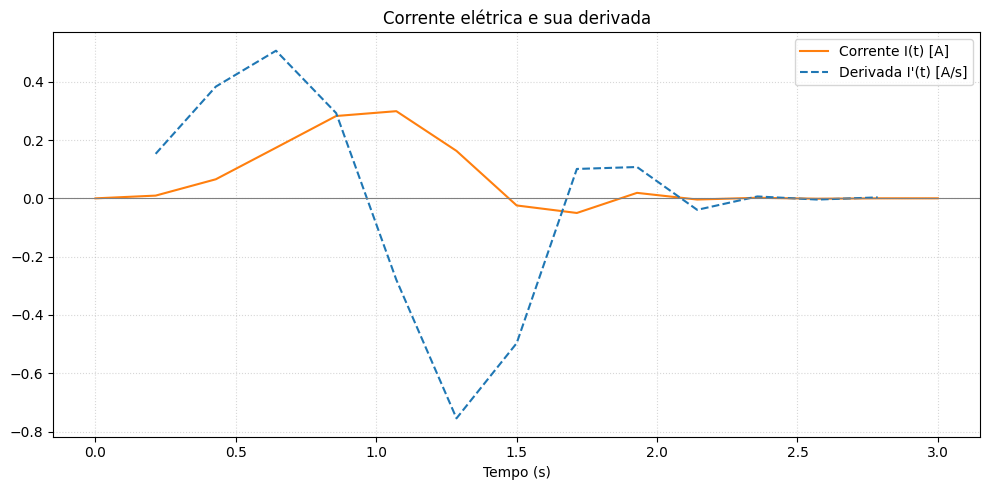

In [ ]:
time_values, current_values = sample_function(
    expression_str="exp(-t**2) * sin(t**3)",
    interval=(0, 3),
    n=15,
)


derivative_times, derivative_values = centered_derivative(
    time_values,
    current_values,
)

plt.figure(figsize=(10, 5))

plt.plot(
    time_values,
    current_values,
    label="Corrente I(t) [A]",
    color="tab:orange",
)

plt.plot(
    derivative_times,
    derivative_values,
    label="Derivada I'(t) [A/s]",
    color="tab:blue",
    linestyle="--",
)

plt.xlabel("Tempo (s)")
plt.title("Corrente elétrica e sua derivada")
plt.axhline(0, color="gray", linewidth=0.8)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Quando a derivada de uma função é positiva, sabemos que a função está crescendo. Quando é negativa, indica que está decrescendo. Portanto, para determinar o ponto $t$ em que a taxa de crescimento da corrente é máxima, basta pegar o tempo em que o valor da derivada é máximo.

Como se trata de uma amostra, o valor será aproximado, ou seja, não é exatamente o $t$ em que a corrente mais cresce, mas está próximo.

In [ ]:
max_index = derivative_values.index(max(derivative_values))
time_max = derivative_times[max_index]

print(f"A corrente cresce mais rápido em t ≈ {time_max:.6f} s.")

A corrente cresce mais rápido em t ≈ 0.642857 s.


### c) Integral com regra de Simpson

In [ ]:
def composite_simpson(time_values, current_values):
    subinterval_count = len(time_values) - 1

    if subinterval_count < 2 or subinterval_count % 2 != 0:
        raise ValueError("O número de subintervalos deve ser positivo e par.")

    step = (time_values[-1] - time_values[0]) / subinterval_count

    endpoint_sum = current_values[0] + current_values[-1]
    odd_sum = sum(current_values[index] for index in range(1, subinterval_count, 2))
    even_sum = sum(current_values[index] for index in range(2, subinterval_count, 2))

    return (step / 3) * (endpoint_sum + 4 * odd_sum + 2 * even_sum)

n =  2 | Q ≈ -0.0486973639 C | Delta (9.99900E+03)
n =  4 | Q ≈ 0.2153082160 C | Delta (2.64006E-01)
n =  6 | Q ≈ 0.1578322488 C | Delta (5.74760E-02)
n =  8 | Q ≈ 0.2173597427 C | Delta (5.95275E-02)
n = 10 | Q ≈ 0.1935481023 C | Delta (2.38116E-02)
n = 12 | Q ≈ 0.2000321436 C | Delta (6.48404E-03)
n = 14 | Q ≈ 0.2017975543 C | Delta (1.76541E-03)
n = 16 | Q ≈ 0.1998080446 C | Delta (1.98951E-03)
n = 18 | Q ≈ 0.1996693631 C | Delta (1.38682E-04)
n = 20 | Q ≈ 0.1999863625 C | Delta (3.16999E-04)
n = 22 | Q ≈ 0.2001238591 C | Delta (1.37497E-04)
n = 24 | Q ≈ 0.2001490828 C | Delta (2.52237E-05)
n = 26 | Q ≈ 0.2001467066 C | Delta (2.37622E-06)
n = 28 | Q ≈ 0.2001423994 C | Delta (4.30723E-06)
n = 30 | Q ≈ 0.2001399003 C | Delta (2.49911E-06)
n = 32 | Q ≈ 0.2001387188 C | Delta (1.18145E-06)
n = 34 | Q ≈ 0.2001382033 C | Delta (5.15488E-07)
n = 36 | Q ≈ 0.2001379952 C | Delta (2.08084E-07)
n = 38 | Q ≈ 0.2001379259 C | Delta (6.93244E-08)
n = 40 | Q ≈ 0.2001379185 C | Delta (7.43867E-09)

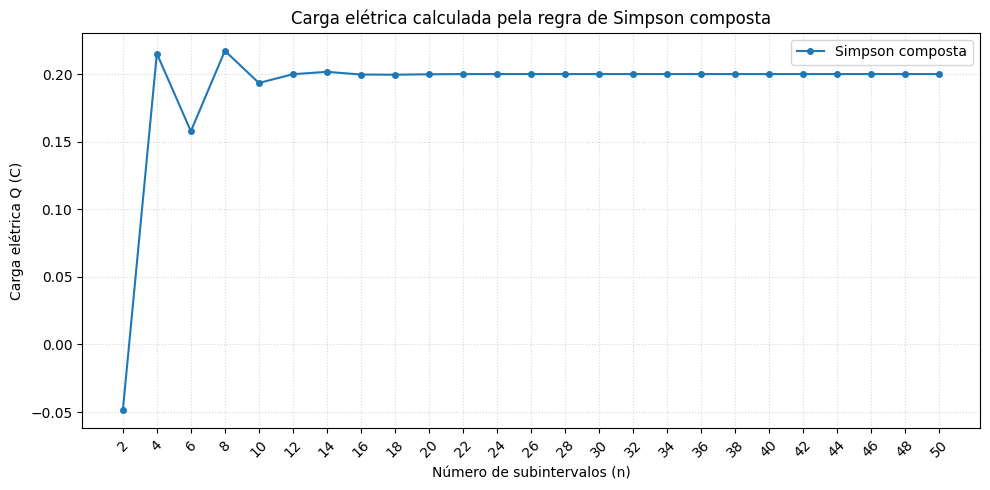

In [ ]:
subinterval_counts = list(range(2, 51, 2))
charge_values = []

for i, subinterval_count in enumerate(subinterval_counts):
    time_values, current_values = sample_function(
        expression_str="exp(-t**2) * sin(t**3)",
        interval=(0, 3),
        n=subinterval_count + 1,
    )

    charge = composite_simpson(time_values, current_values)
    charge_values.append(charge)
    delta = abs(charge - charge_values[i - 1]) if i > 0 else 9999

    print(f"n = {subinterval_count:2d} | Q ≈ {charge:.10f} C | Delta ({delta:.5E})")


plt.figure(figsize=(10, 5))
plt.plot(
    subinterval_counts,
    charge_values,
    marker="o",
    markersize=4,
    label="Simpson composta",
)

plt.xlabel("Número de subintervalos (n)")
plt.ylabel("Carga elétrica Q (C)")
plt.title("Carga elétrica calculada pela regra de Simpson composta")
plt.xticks(subinterval_counts, rotation=45)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Como esperado, o uso de mais pontos aproxima o resultado da resposta correta. Mas a partir de um certo ponto, o ganho em função do crescimento do n desaparece.